In [1]:
from autogradWN import Tensor, MLP, Dense, SoftmaxCCE, MSE, SGD, Adam, BCE
import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [2]:
# Baixando os datasets
mnist = fetch_openml("mnist_784", version=1, as_frame=False)
boston = fetch_openml("boston", version=1, as_frame=False)

# MNIST: pixels normalizados entre 0 e 1
X_mnist = np.asarray(mnist.data, dtype=np.float64) / 255.0
y_mnist = np.asarray(mnist.target, dtype=int)

# Selecionando 120 exemplos de cada classe
rng = np.random.default_rng(42)

indices = np.concatenate([
    rng.choice(np.where(y_mnist == classe)[0], 120, replace=False)
    for classe in range(10)
])

X_mnist = X_mnist[indices]
y_mnist = y_mnist[indices]

# Divisão treino/teste (80/20)
X_mnist_train, X_mnist_test, y_mnist_train, y_mnist_test = train_test_split(
    X_mnist, y_mnist,
    test_size=0.2, stratify=y_mnist, random_state=42
)

X_boston_train, X_boston_test, y_boston_train, y_boston_test = train_test_split(
    np.asarray(boston.data, dtype=float),
    np.asarray(boston.target, dtype=float).reshape(-1, 1),
    test_size=0.2, random_state=42
)

# Padronização do Boston
scaler_boston = StandardScaler()
X_boston_train = scaler_boston.fit_transform(X_boston_train)
X_boston_test = scaler_boston.transform(X_boston_test)

# Convertendo para tensores
def criar_tensor(dados):
    tensor = Tensor(dados.shape)
    tensor.peso = dados
    return tensor

X_mnist_train = criar_tensor(X_mnist_train)
X_mnist_test = criar_tensor(X_mnist_test)
y_mnist_train = criar_tensor(y_mnist_train)
y_mnist_test = criar_tensor(y_mnist_test)

X_boston_train = criar_tensor(X_boston_train)
X_boston_test = criar_tensor(X_boston_test)
y_boston_train = criar_tensor(y_boston_train)
y_boston_test = criar_tensor(y_boston_test)

In [3]:
print(X_mnist_train.peso.shape)    # (960, 784)
print(y_mnist_train.peso.shape)    # (960,)

print(X_boston_train.peso.shape)  # (404, 13)
print(y_boston_train.peso.shape)  # (404, 1)

(960, 784)
(960,)
(404, 13)
(404, 1)


In [4]:
print(X_mnist_train)

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


In [5]:
print(X_boston_train)

[[ 1.28770177 -0.50032012  1.03323679 ...  0.84534281 -0.07433689
   1.75350503]
 [-0.33638447 -0.50032012 -0.41315956 ...  1.20474139  0.4301838
  -0.5614742 ]
 [-0.40325332  1.01327135 -0.71521823 ... -0.63717631  0.06529747
  -0.65159505]
 ...
 [-0.40547014  2.95931752 -1.30336132 ... -0.59225149  0.37901005
  -0.91069248]
 [ 0.85189733 -0.50032012  1.03323679 ...  0.84534281 -2.69458597
   1.52257036]
 [-0.38135592 -0.50032012 -0.35216694 ...  1.15981657 -3.12158061
  -0.25731635]]


In [6]:
# Função para plotar histogramas    
def limpar_historicos(modelo):
    modelo.limpar_historicos()
    



def plotar_histogramas(modelo, epoca):
    n = len(modelo.camadas)
    fig, axes = plt.subplots(n, 2, figsize=(12, 3*n))

    for i in range(n):
        # Ativações
        ativacoes = modelo.obter_ativacoes(i)

        axes[i, 0].hist(
            ativacoes, bins=50,
            weights=np.ones(len(ativacoes)) / len(ativacoes)
        )
        axes[i, 0].set_title(f"Camada {i+1} - Ativações")
        axes[i, 0].set_xlabel("Valor da ativação")
        axes[i, 0].set_ylabel("Frequência relativa")

        # Gradientes em escala logarítmica
        gradientes = np.abs(
            modelo.obter_gradientes(i)
        )

        log_gradientes = np.log10(gradientes + 1e-15)

        axes[i, 1].hist(
            log_gradientes,
            bins=np.linspace(-15, 5, 81),
            weights=np.ones(len(log_gradientes)) / len(log_gradientes)
        )
        axes[i, 1].set_title(f"Camada {i+1} - Gradientes")
        axes[i, 1].set_xlabel("log10(|gradiente|)")
        axes[i, 1].set_ylabel("Frequência relativa")
        axes[i, 1].set_xlim(-15, 5)

    fig.suptitle(f"Época {epoca}", fontsize=14)
    plt.tight_layout()
    plt.show()


# Treinamento no House boston

Época: 1 | Loss: 83.953 | Val_Loss: 31.067 | R²: 0.0336 | Val_R²: 0.5764


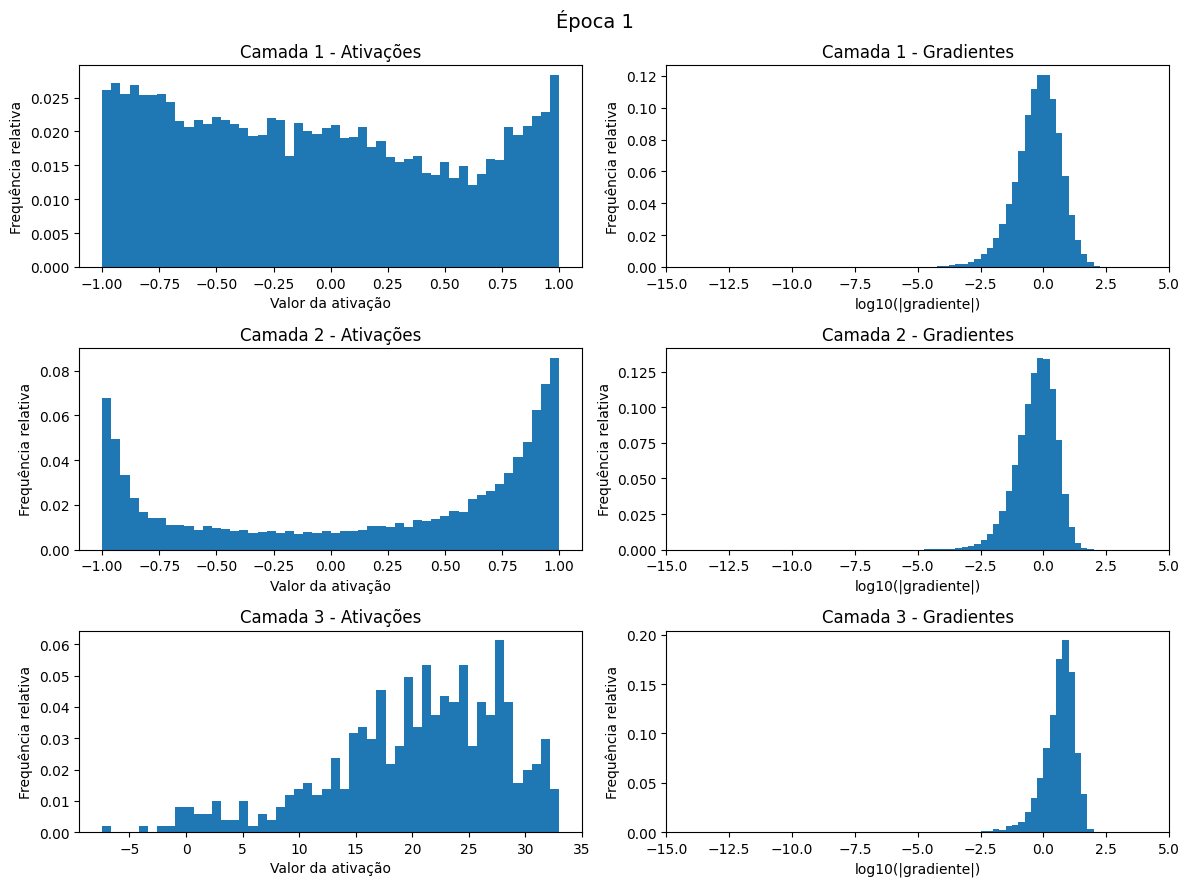

Época: 2 | Loss: 28.087 | Val_Loss: 20.269 | R²: 0.6767 | Val_R²: 0.7236
Época: 3 | Loss: 18.774 | Val_Loss: 18.763 | R²: 0.7839 | Val_R²: 0.7441
Época: 4 | Loss: 15.188 | Val_Loss: 16.455 | R²: 0.8252 | Val_R²: 0.7756
Época: 5 | Loss: 13.031 | Val_Loss: 18.435 | R²: 0.8500 | Val_R²: 0.7486
Época: 6 | Loss: 11.343 | Val_Loss: 15.111 | R²: 0.8694 | Val_R²: 0.7939
Época: 7 | Loss: 9.630 | Val_Loss: 14.376 | R²: 0.8891 | Val_R²: 0.8040
Época: 8 | Loss: 8.723 | Val_Loss: 14.063 | R²: 0.8996 | Val_R²: 0.8082
Época: 9 | Loss: 8.126 | Val_Loss: 14.059 | R²: 0.9065 | Val_R²: 0.8083
Época: 10 | Loss: 7.638 | Val_Loss: 13.994 | R²: 0.9121 | Val_R²: 0.8092
Época: 11 | Loss: 7.177 | Val_Loss: 13.772 | R²: 0.9174 | Val_R²: 0.8122
Época: 12 | Loss: 6.831 | Val_Loss: 13.447 | R²: 0.9214 | Val_R²: 0.8166
Época: 13 | Loss: 6.520 | Val_Loss: 13.029 | R²: 0.9249 | Val_R²: 0.8223
Época: 14 | Loss: 6.232 | Val_Loss: 12.680 | R²: 0.9283 | Val_R²: 0.8271
Época: 15 | Loss: 5.958 | Val_Loss: 12.418 | R²: 0.931

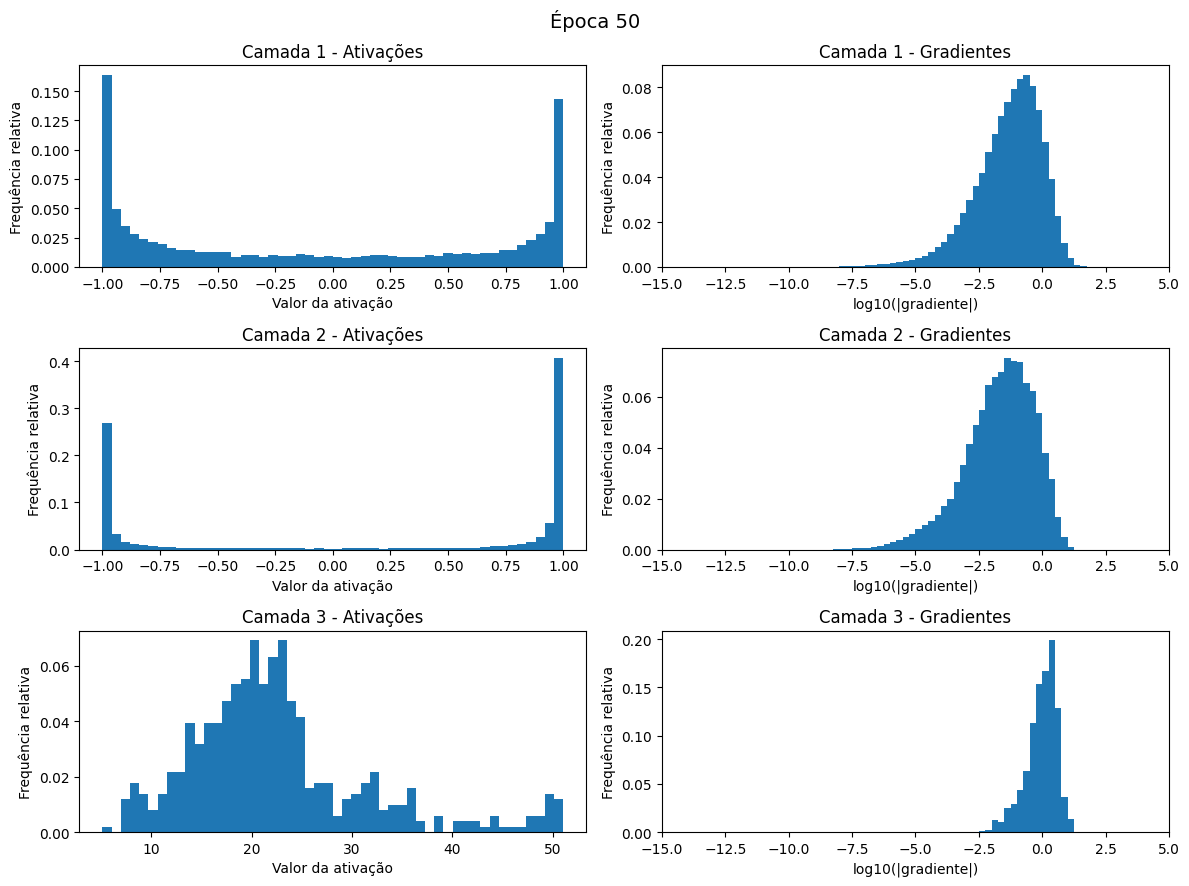

Época: 51 | Loss: 2.141 | Val_Loss: 9.885 | R²: 0.9754 | Val_R²: 0.8652
Época: 52 | Loss: 2.064 | Val_Loss: 10.019 | R²: 0.9762 | Val_R²: 0.8634
Época: 53 | Loss: 2.034 | Val_Loss: 9.947 | R²: 0.9766 | Val_R²: 0.8644
Época: 54 | Loss: 1.983 | Val_Loss: 9.953 | R²: 0.9772 | Val_R²: 0.8643
Época: 55 | Loss: 1.942 | Val_Loss: 10.032 | R²: 0.9776 | Val_R²: 0.8632
Época: 56 | Loss: 1.947 | Val_Loss: 9.810 | R²: 0.9776 | Val_R²: 0.8662
Época: 57 | Loss: 1.989 | Val_Loss: 10.179 | R²: 0.9771 | Val_R²: 0.8612
Época: 58 | Loss: 2.114 | Val_Loss: 9.556 | R²: 0.9757 | Val_R²: 0.8697
Época: 59 | Loss: 2.213 | Val_Loss: 10.454 | R²: 0.9745 | Val_R²: 0.8575
Época: 60 | Loss: 1.999 | Val_Loss: 9.924 | R²: 0.9770 | Val_R²: 0.8647
Época: 61 | Loss: 1.872 | Val_Loss: 10.677 | R²: 0.9785 | Val_R²: 0.8544
Época: 62 | Loss: 1.828 | Val_Loss: 10.228 | R²: 0.9790 | Val_R²: 0.8605
Época: 63 | Loss: 1.738 | Val_Loss: 10.612 | R²: 0.9800 | Val_R²: 0.8553
Época: 64 | Loss: 1.726 | Val_Loss: 10.384 | R²: 0.9801 |

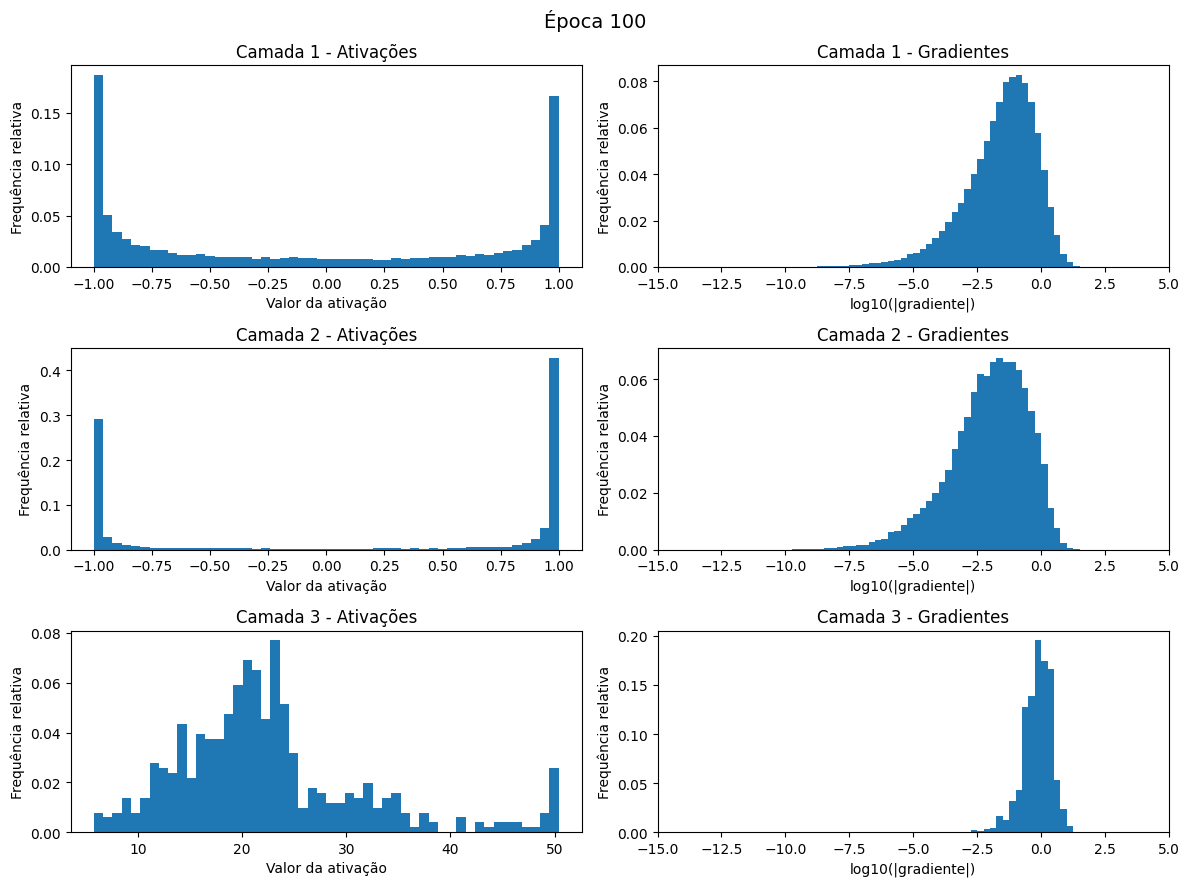

Época: 101 | Loss: 1.222 | Val_Loss: 10.796 | R²: 0.9859 | Val_R²: 0.8528
Época: 102 | Loss: 1.222 | Val_Loss: 10.817 | R²: 0.9859 | Val_R²: 0.8525
Época: 103 | Loss: 1.214 | Val_Loss: 10.937 | R²: 0.9860 | Val_R²: 0.8509
Época: 104 | Loss: 1.260 | Val_Loss: 10.755 | R²: 0.9855 | Val_R²: 0.8533
Época: 105 | Loss: 1.246 | Val_Loss: 10.823 | R²: 0.9857 | Val_R²: 0.8524
Época: 106 | Loss: 1.272 | Val_Loss: 11.131 | R²: 0.9854 | Val_R²: 0.8482
Época: 107 | Loss: 1.255 | Val_Loss: 10.953 | R²: 0.9855 | Val_R²: 0.8506
Época: 108 | Loss: 1.176 | Val_Loss: 10.919 | R²: 0.9865 | Val_R²: 0.8511
Época: 109 | Loss: 1.218 | Val_Loss: 11.252 | R²: 0.9860 | Val_R²: 0.8466
Época: 110 | Loss: 1.198 | Val_Loss: 11.035 | R²: 0.9862 | Val_R²: 0.8495
Época: 111 | Loss: 1.125 | Val_Loss: 10.993 | R²: 0.9871 | Val_R²: 0.8501
Época: 112 | Loss: 1.118 | Val_Loss: 11.317 | R²: 0.9871 | Val_R²: 0.8457
Época: 113 | Loss: 1.118 | Val_Loss: 11.126 | R²: 0.9871 | Val_R²: 0.8483
Época: 114 | Loss: 1.061 | Val_Loss: 1

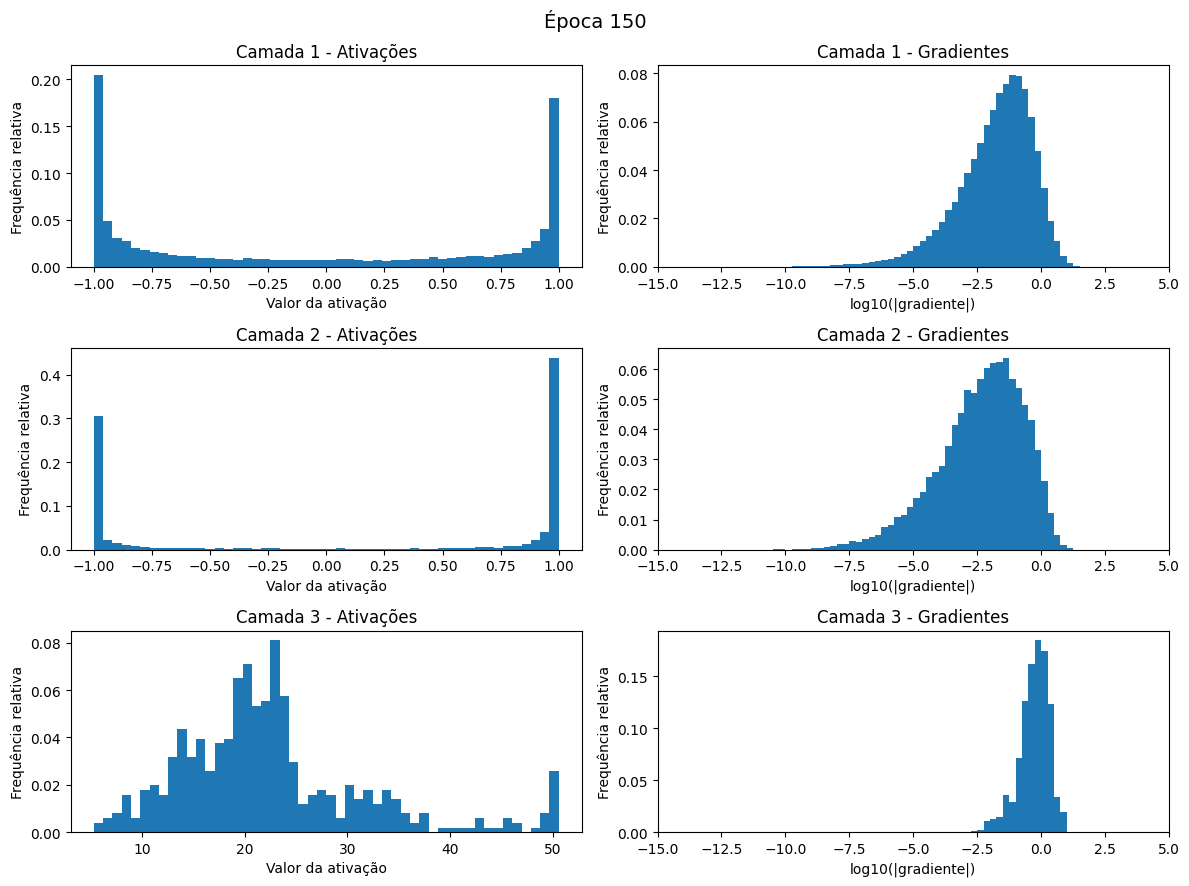

In [7]:
modelo_boston = MLP(
    (Dense(13, 32, "Xavier"), True, "tanh"),
    (Dense(32, 32, "Xavier"), True, "tanh"),
    (Dense(32, 1, "Xavier"), True, "linear")
)

modelo_boston.ativar_monitoramento()

otimizador = SGD(modelo_boston, 0.001)

epocas = 150

historico_treino = []
historico_test = []
historico_r2_treino = []
historico_r2_test = []

for epoca in range(epocas):
    limpar_historicos(modelo_boston)
    
    # Treino
    total_loss = []
    predicoes_treino = []
    reais_treino = []

    for i in range(X_boston_train.peso.shape[0]):
        predicao = modelo_boston(X_boston_train[i:i+1])
        loss = MSE(y_boston_train[i:i+1], predicao)

        predicoes_treino.append(float(predicao.peso.item()))
        reais_treino.append(float(y_boston_train.peso[i, 0]))

        loss.backward()
        otimizador.passo()
        modelo_boston.zerar_gradiente()

        total_loss.append(float(loss.peso))

    # Validação
    validation_loss = []
    predicoes_test = []
    reais_test = []

    for i in range(X_boston_test.peso.shape[0]):
        predicao = modelo_boston(X_boston_test[i:i+1])
        loss = MSE(y_boston_test[i:i+1], predicao)

        predicoes_test.append(float(predicao.peso.item()))
        reais_test.append(float(y_boston_test.peso[i, 0]))

        validation_loss.append(float(loss.peso))

    r2_treino = r2_score(reais_treino, predicoes_treino)
    r2_test = r2_score(reais_test, predicoes_test)

    historico_treino.append(np.mean(total_loss))
    historico_test.append(np.mean(validation_loss))
    historico_r2_treino.append(r2_treino)
    historico_r2_test.append(r2_test)

    print(
        f"Época: {epoca + 1} | "
        f"Loss: {np.mean(total_loss):.3f} | "
        f"Val_Loss: {np.mean(validation_loss):.3f} | "
        f"R²: {r2_treino:.4f} | "
        f"Val_R²: {r2_test:.4f}"
    )
    
    if (epoca + 1) % 50 == 0 or epoca == epocas - 1 or epoca == 0:
            plotar_histogramas(modelo_boston, epoca + 1) 


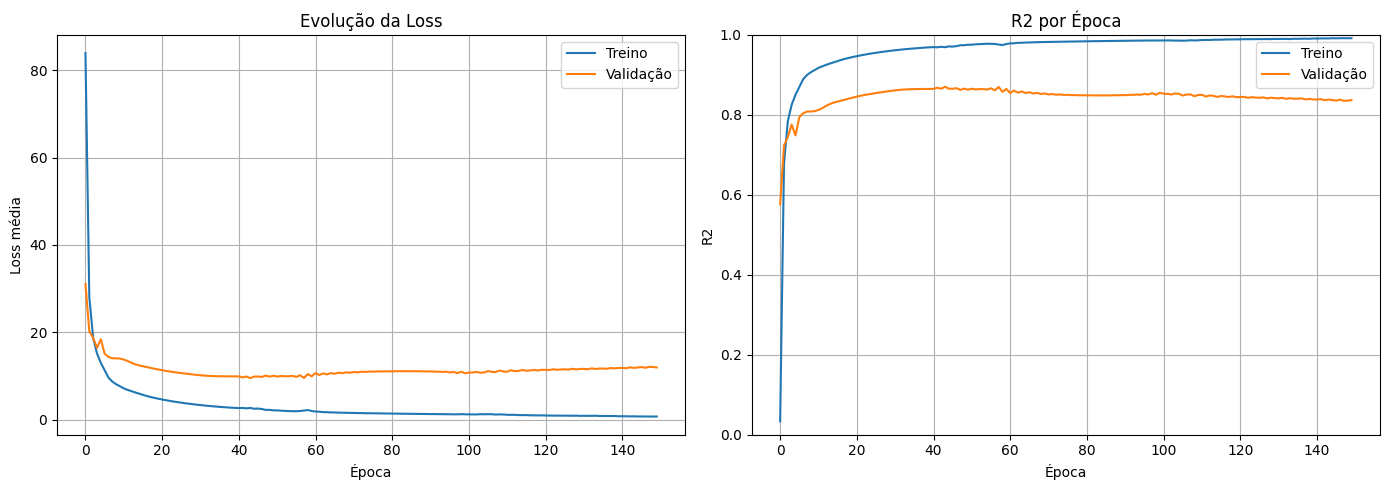

In [8]:
#Plot loss e R2

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(historico_treino, label="Treino")
axes[0].plot(historico_test, label="Validação")
axes[0].set_title("Evolução da Loss")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss média")
axes[0].legend()
axes[0].grid(True)

# R2
axes[1].plot(historico_r2_treino, label="Treino")
axes[1].plot(historico_r2_test, label="Validação")
axes[1].set_title("R2 por Época")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("R2")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Treinando mnsit

Época: 1 | Loss: 0.967 | Val_Loss: 0.519 | Acc: 68.33% | Val_Acc: 77.92%


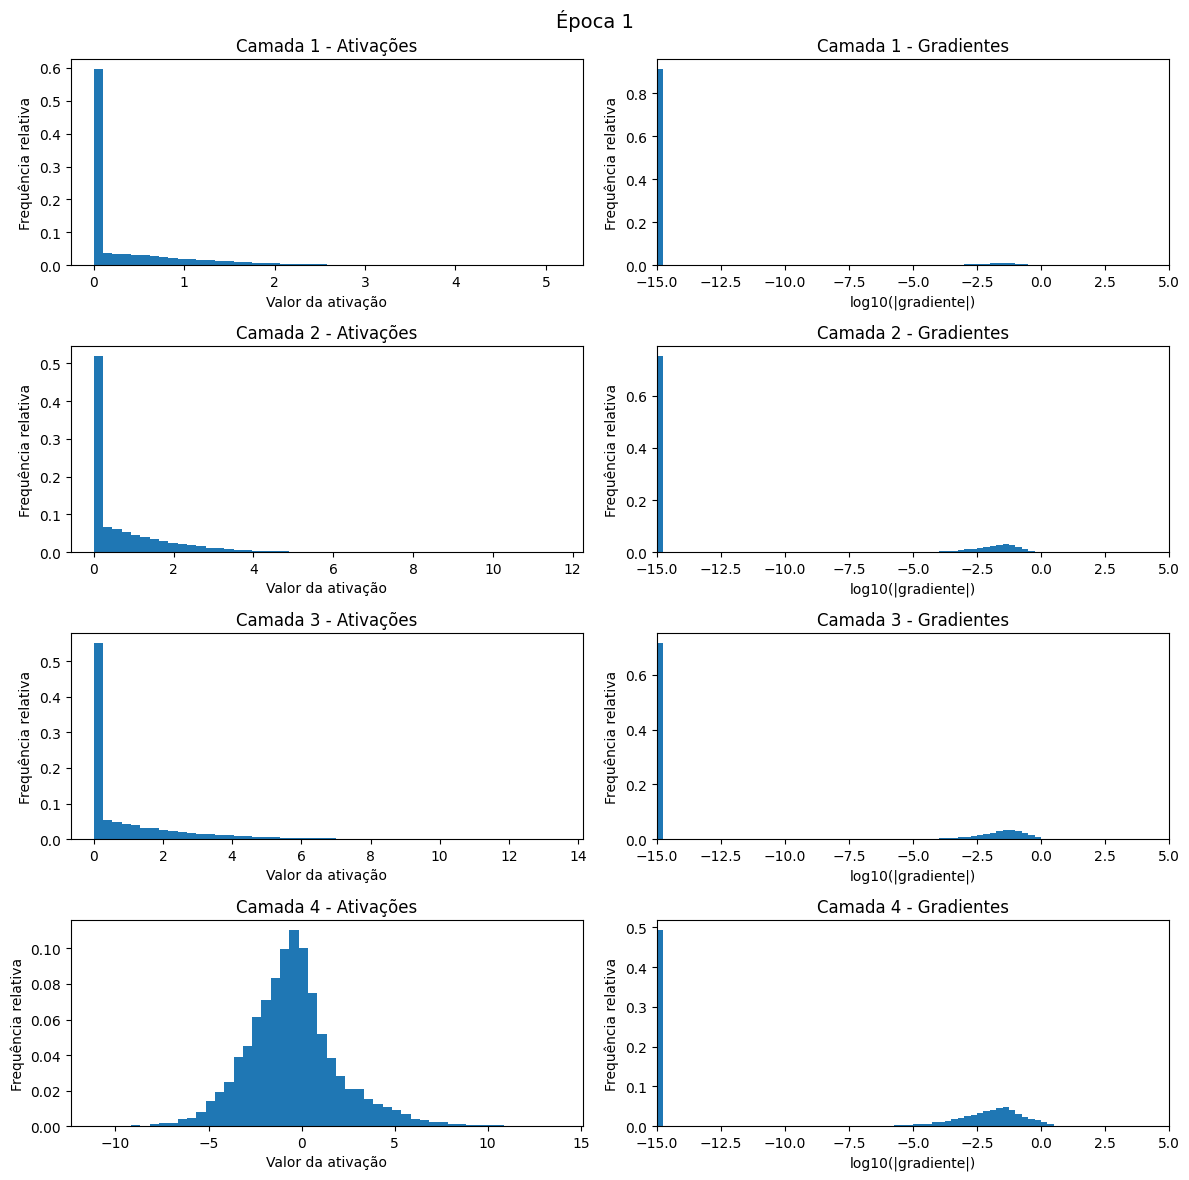

Época: 2 | Loss: 0.378 | Val_Loss: 0.437 | Acc: 87.19% | Val_Acc: 84.58%


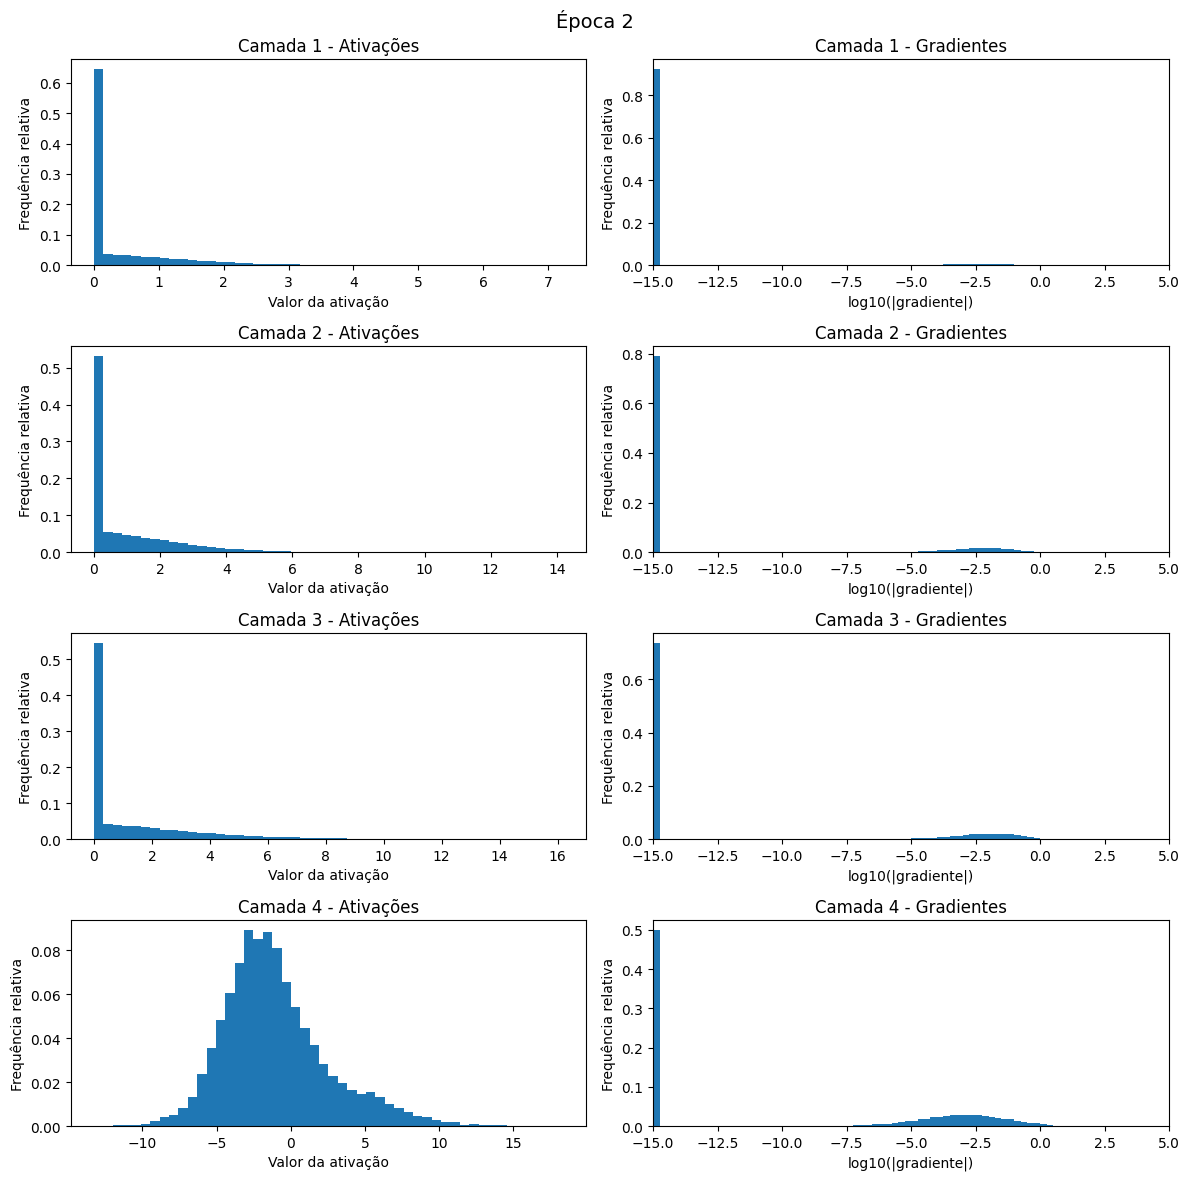

Época: 3 | Loss: 0.246 | Val_Loss: 0.461 | Acc: 91.88% | Val_Acc: 85.42%
Época: 4 | Loss: 0.171 | Val_Loss: 0.574 | Acc: 94.69% | Val_Acc: 84.58%


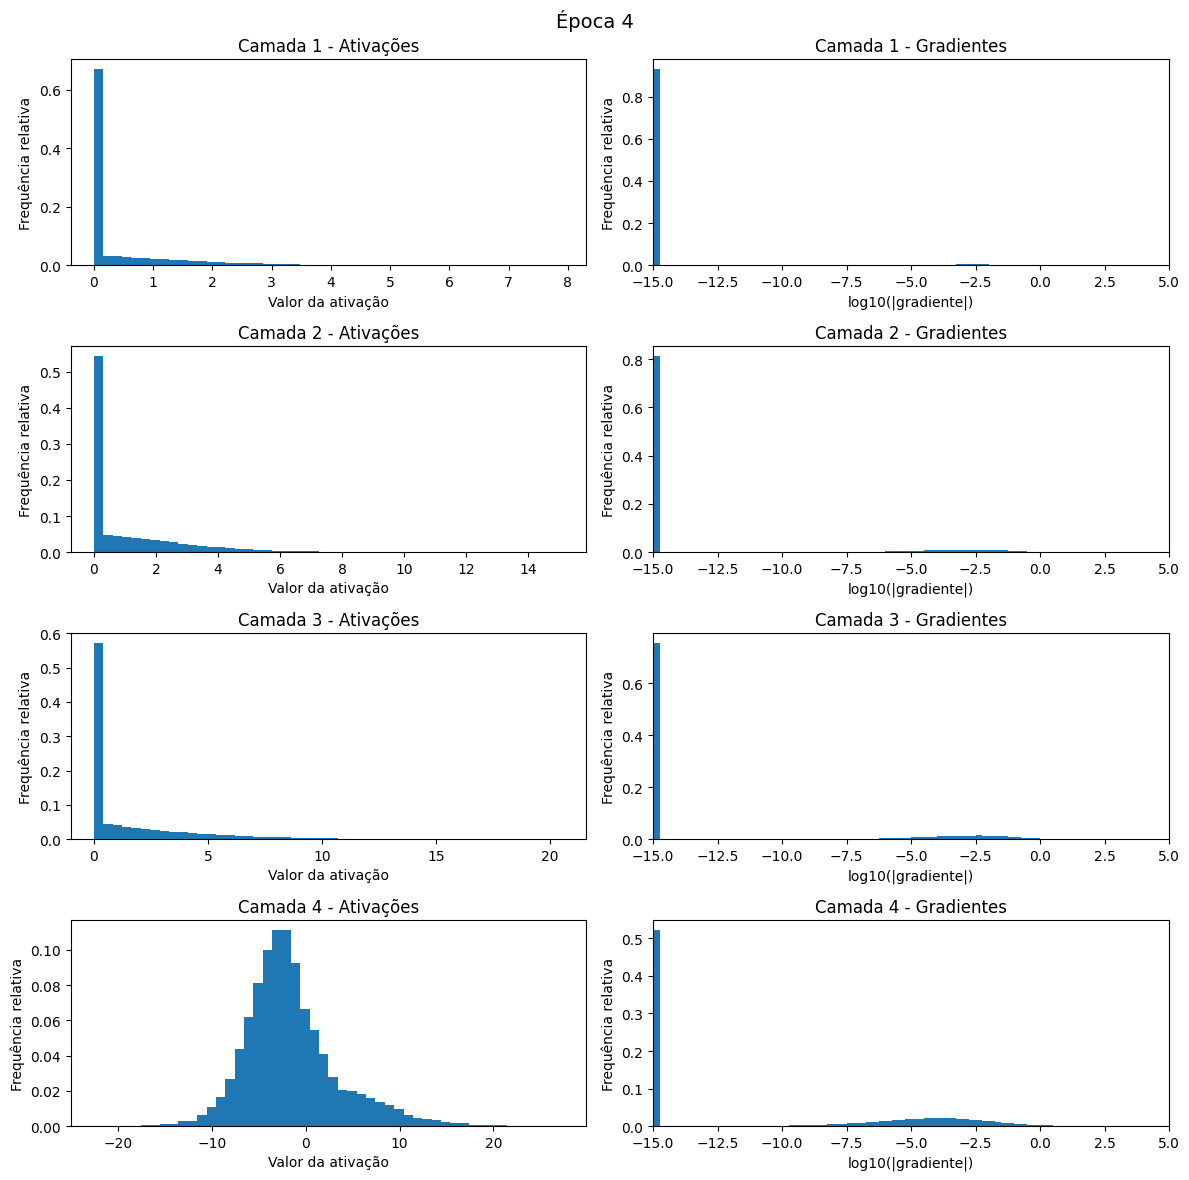

Época: 5 | Loss: 0.143 | Val_Loss: 0.535 | Acc: 95.42% | Val_Acc: 85.83%


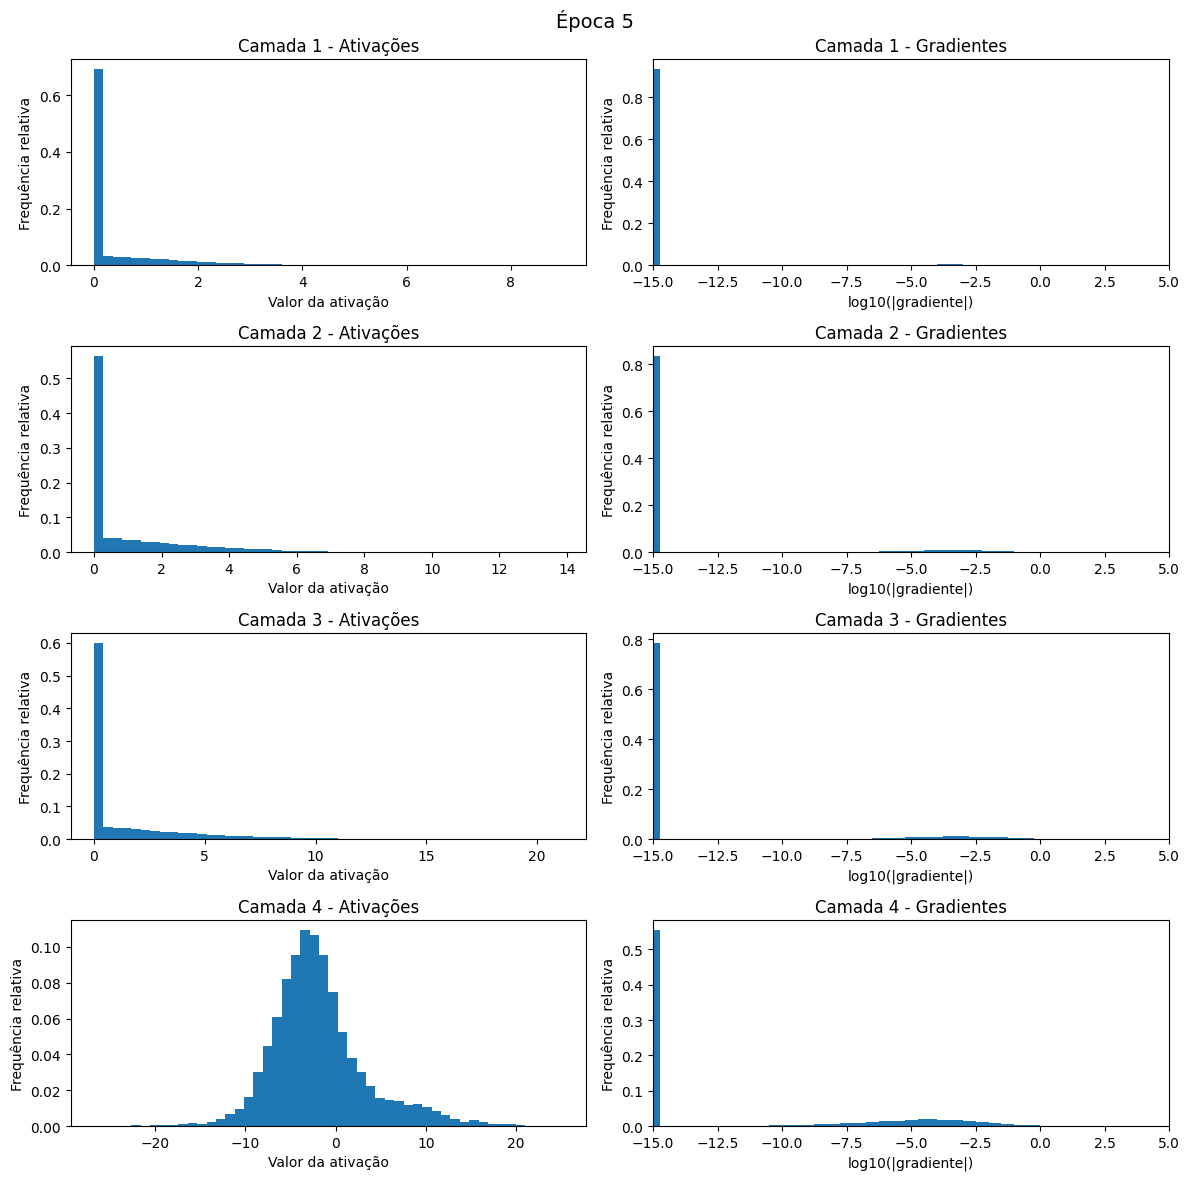

In [9]:
modelo_mnist = MLP(
    (Dense(784, 128, "He"), True, "reLU"),
    (Dense(128, 64, "He"), True, "reLU"),
    (Dense(64, 32, "He"), True, "reLU"),
    (Dense(32, 10, "Xavier"), True, "linear")
)

modelo_mnist.ativar_monitoramento()

otimizador = Adam(modelo_mnist, 0.001)

modelo_mnist.ativar_monitoramento()

otimizador = Adam(modelo_mnist, 0.001)

epocas = 5

# Guardar infomações para gerar os gráficos
historico_treino = []
historico_test = []
historico_acc_treino = []
historico_acc_test = []


for epoca in range(epocas):
    limpar_historicos(modelo_mnist)  # Para limpar os histogramas
    
    # treino
    total_loss = []
    acertos_treino = []
    for i in range(X_mnist_train.peso.shape[0]):
        logits = modelo_mnist(X_mnist_train[i:i+1])
        loss = SoftmaxCCE(y_mnist_train[i], logits)
        
        acertos_treino.append(int(np.argmax(logits.peso) == y_mnist_train.peso[i]))
        
        loss.backward()
        
        otimizador.passo()
        
        modelo_mnist.zerar_gradiente()
        
        total_loss.append(float(loss.peso))
    
    # Validação
    validation_loss = []
    acertos_test = []
    for i in range(X_mnist_test.peso.shape[0]):
        logits = modelo_mnist(X_mnist_test[i:i+1])
        loss = SoftmaxCCE(y_mnist_test[i], logits)
        
        acertos_test.append(int(np.argmax(logits.peso) == y_mnist_test.peso[i]))
    
        
        validation_loss.append(float(loss.peso)) 
    
    historico_treino.append(np.mean(total_loss))
    historico_test.append(np.mean(validation_loss))
    historico_acc_treino.append(np.mean(acertos_treino))   
    historico_acc_test.append(np.mean(acertos_test)) 
    
    print(
    f"Época: {epoca + 1} | "
    f"Loss: {np.mean(total_loss):.3f} | "
    f"Val_Loss: {np.mean(validation_loss):.3f} | "
    f"Acc: {np.mean(acertos_treino):.2%} | "
    f"Val_Acc: {np.mean(acertos_test):.2%}"
    )
    
    if (epoca + 1) % 2 == 0 or epoca == epocas - 1 or epoca == 0:
        plotar_histogramas(modelo_mnist, epoca + 1)    

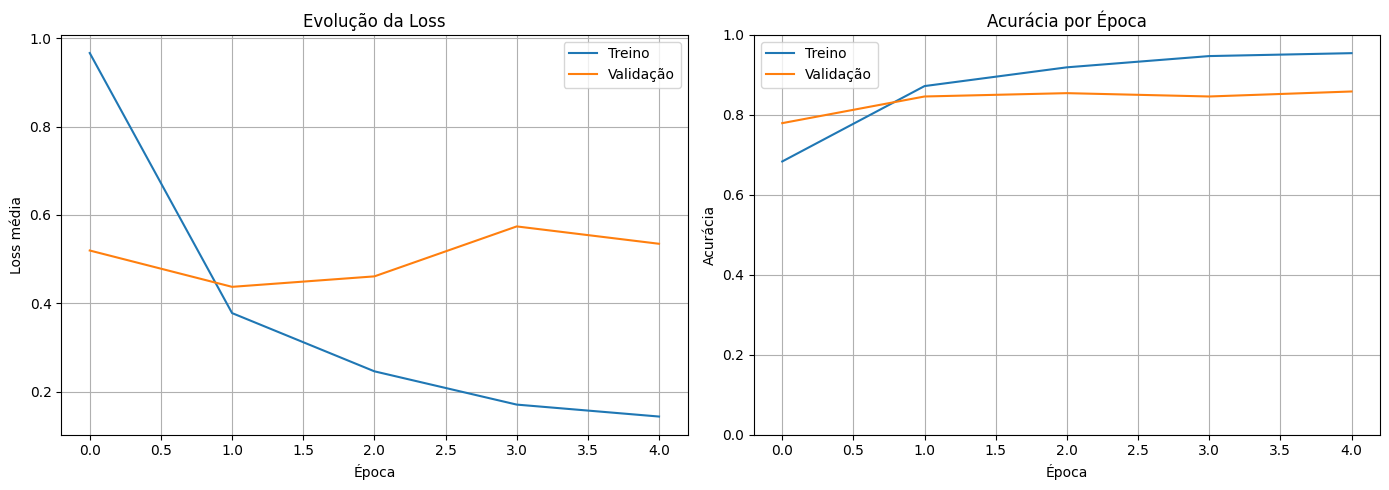

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(historico_treino, label="Treino")
axes[0].plot(historico_test, label="Validação")
axes[0].set_title("Evolução da Loss")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss média")
axes[0].legend()
axes[0].grid(True)

# Acurácia
axes[1].plot(historico_acc_treino, label="Treino")
axes[1].plot(historico_acc_test, label="Validação")
axes[1].set_title("Acurácia por Época")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Acurácia")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [11]:
modelo_mnist.save("./Aqui")

In [12]:
a = MLP.load("Aqui.npz")

In [13]:
print(a(X_mnist_train[1]))
print(y_mnist_train[1])

[[-3.96607563 -8.8858577   0.19319225 -9.4289376  19.87249546  0.57139934
   4.14678139 -6.37793607 -3.91547982  0.43548586]]
4.0


# Mostrando o gradiente vanishing

Época: 1 | Loss: 2.346 | Val_Loss: 2.312 | Acc: 9.17% | Val_Acc: 10.00%


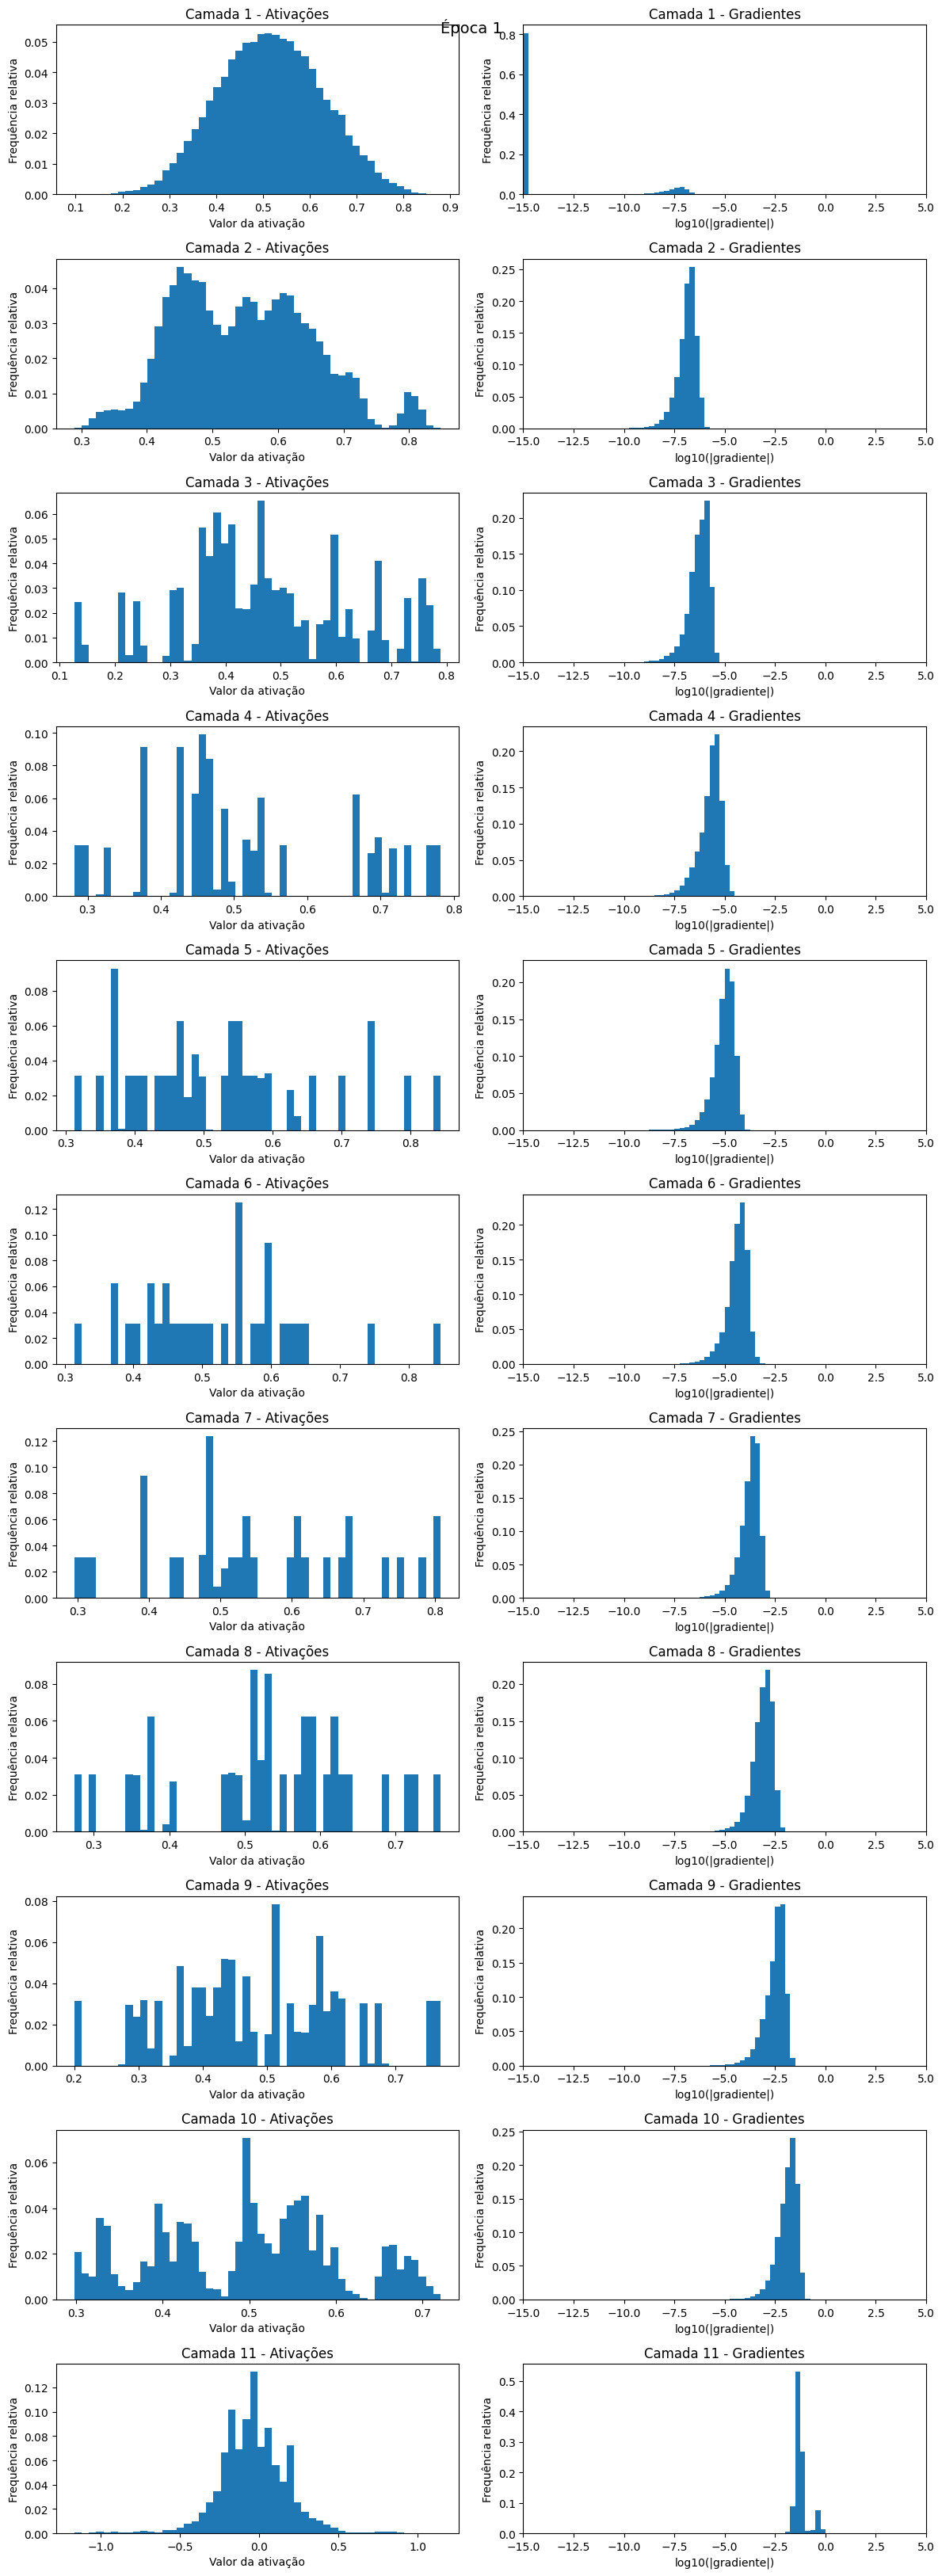

Época: 2 | Loss: 2.332 | Val_Loss: 2.312 | Acc: 8.54% | Val_Acc: 10.00%


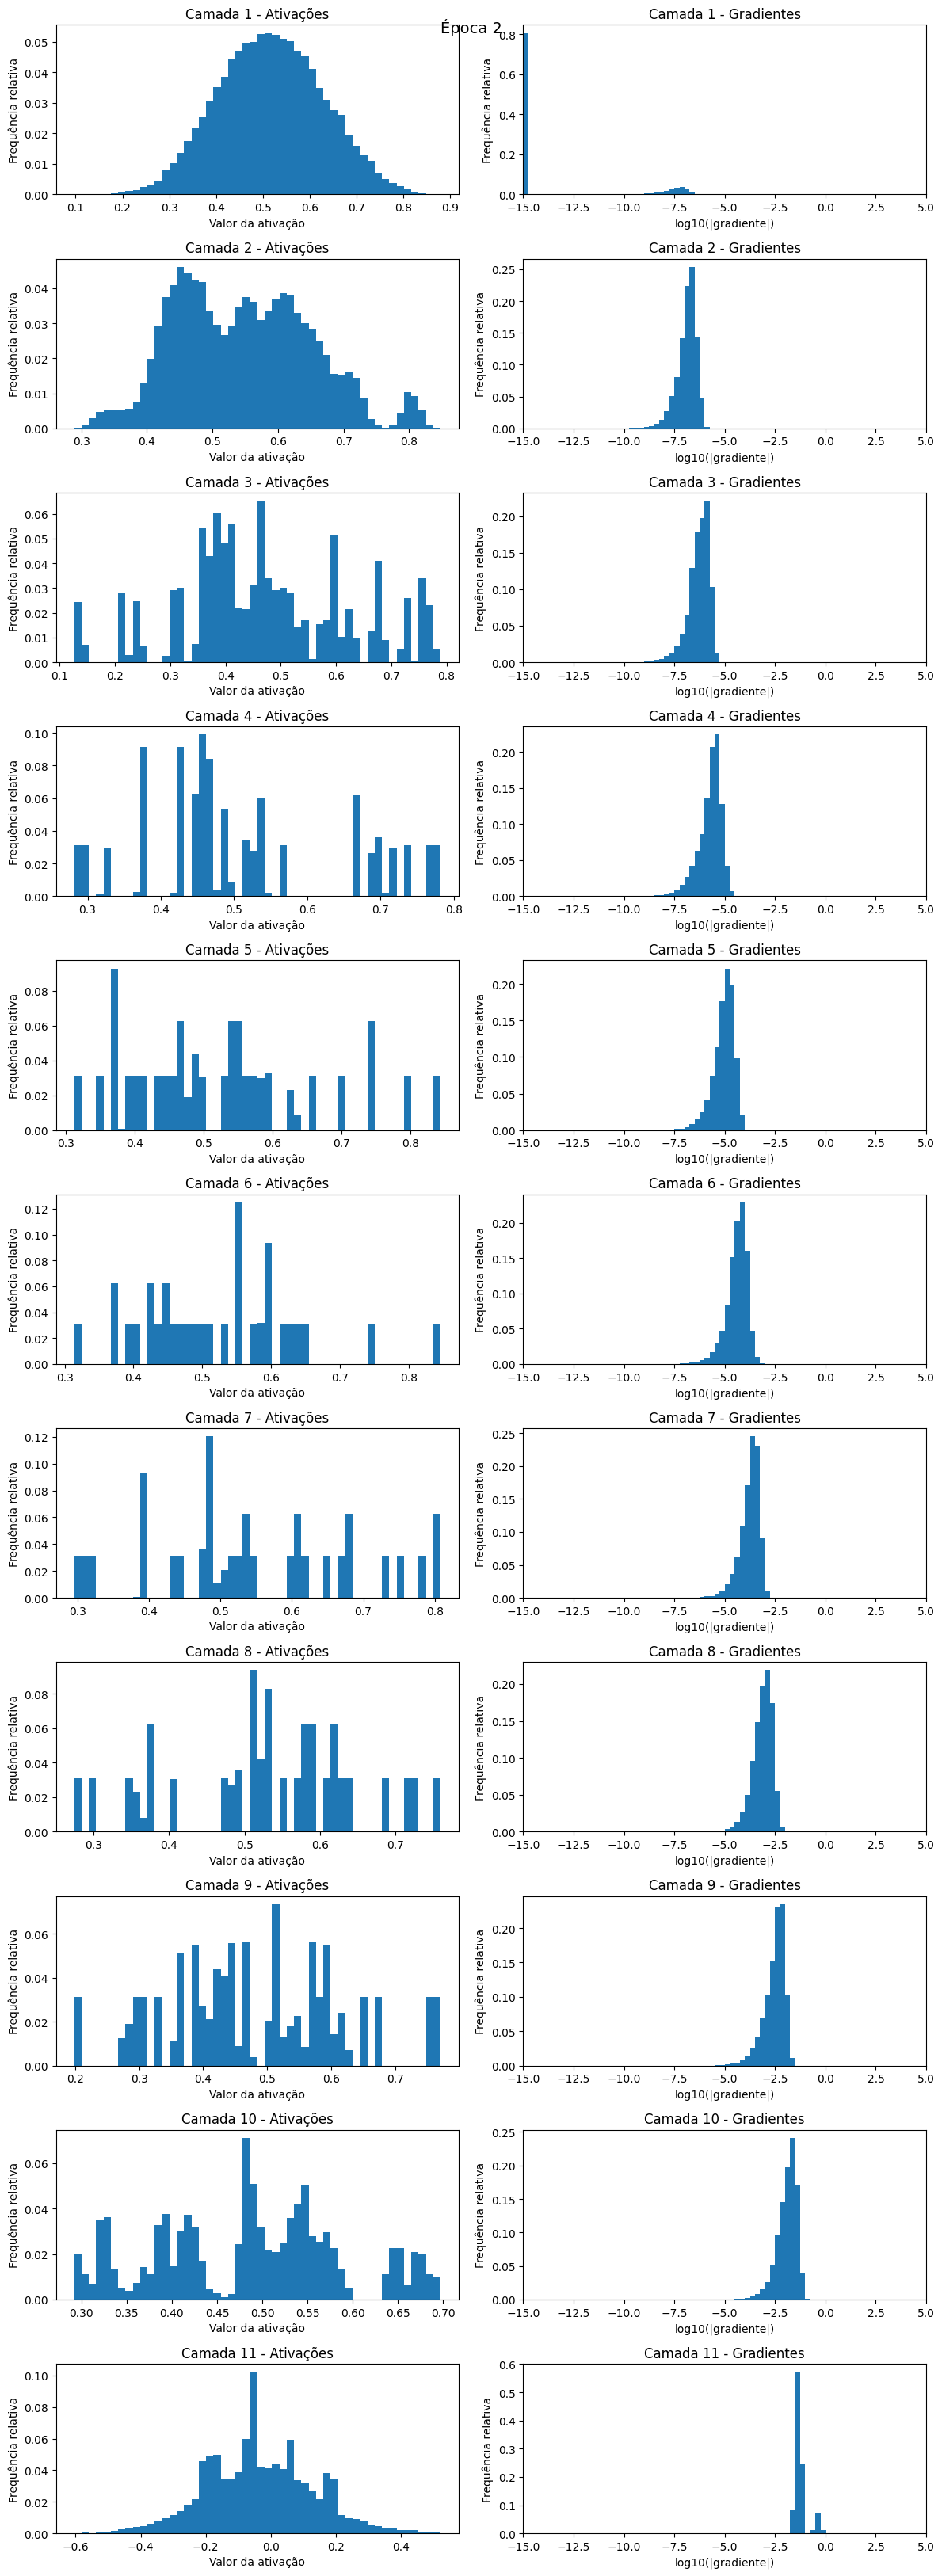

Época: 3 | Loss: 2.331 | Val_Loss: 2.312 | Acc: 8.54% | Val_Acc: 10.00%
Época: 4 | Loss: 2.330 | Val_Loss: 2.311 | Acc: 8.44% | Val_Acc: 10.00%


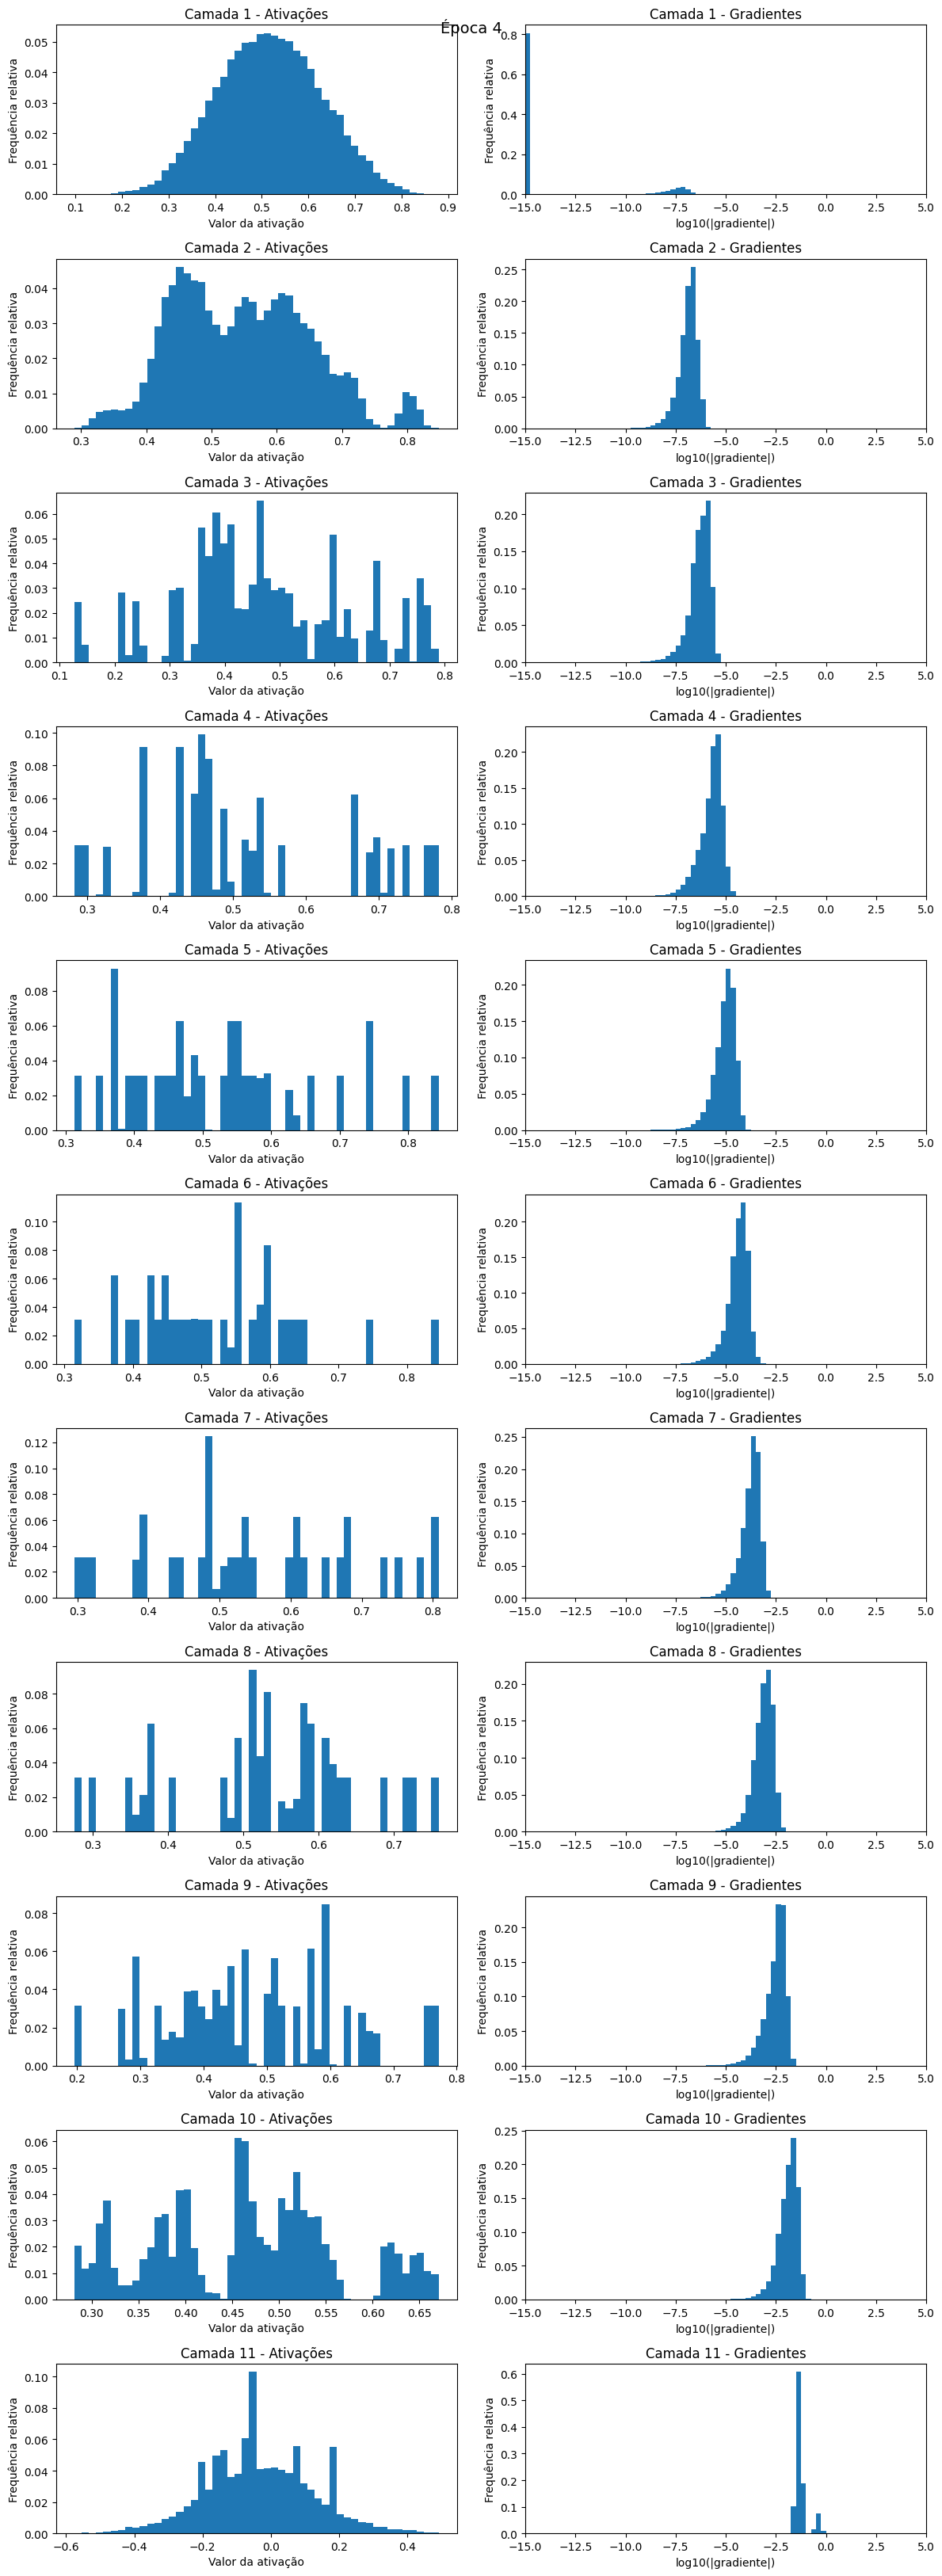

Época: 5 | Loss: 2.329 | Val_Loss: 2.311 | Acc: 8.33% | Val_Acc: 10.00%
Época: 6 | Loss: 2.329 | Val_Loss: 2.310 | Acc: 8.33% | Val_Acc: 10.00%


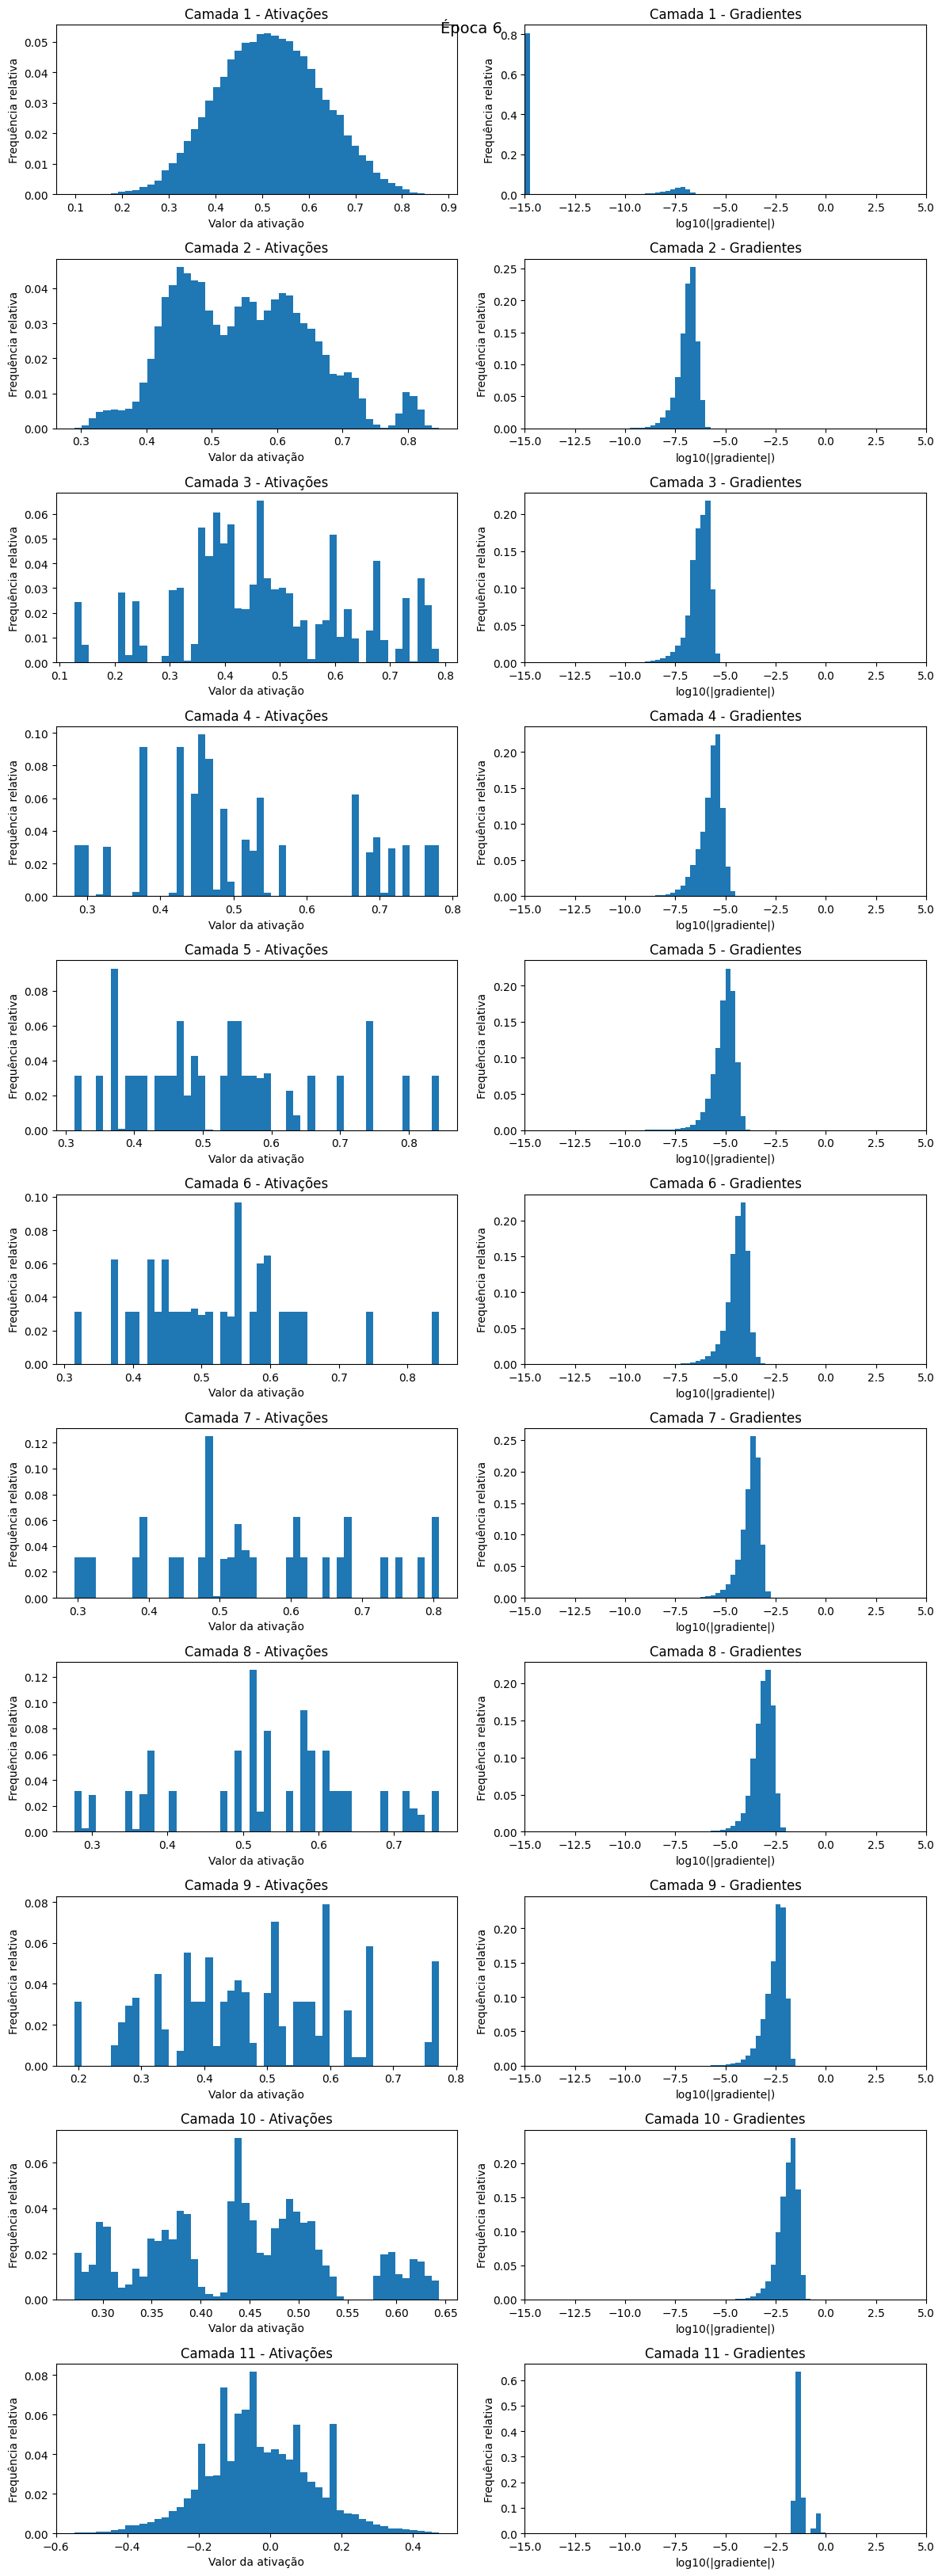

Época: 7 | Loss: 2.328 | Val_Loss: 2.310 | Acc: 8.54% | Val_Acc: 10.00%
Época: 8 | Loss: 2.327 | Val_Loss: 2.310 | Acc: 8.54% | Val_Acc: 10.00%


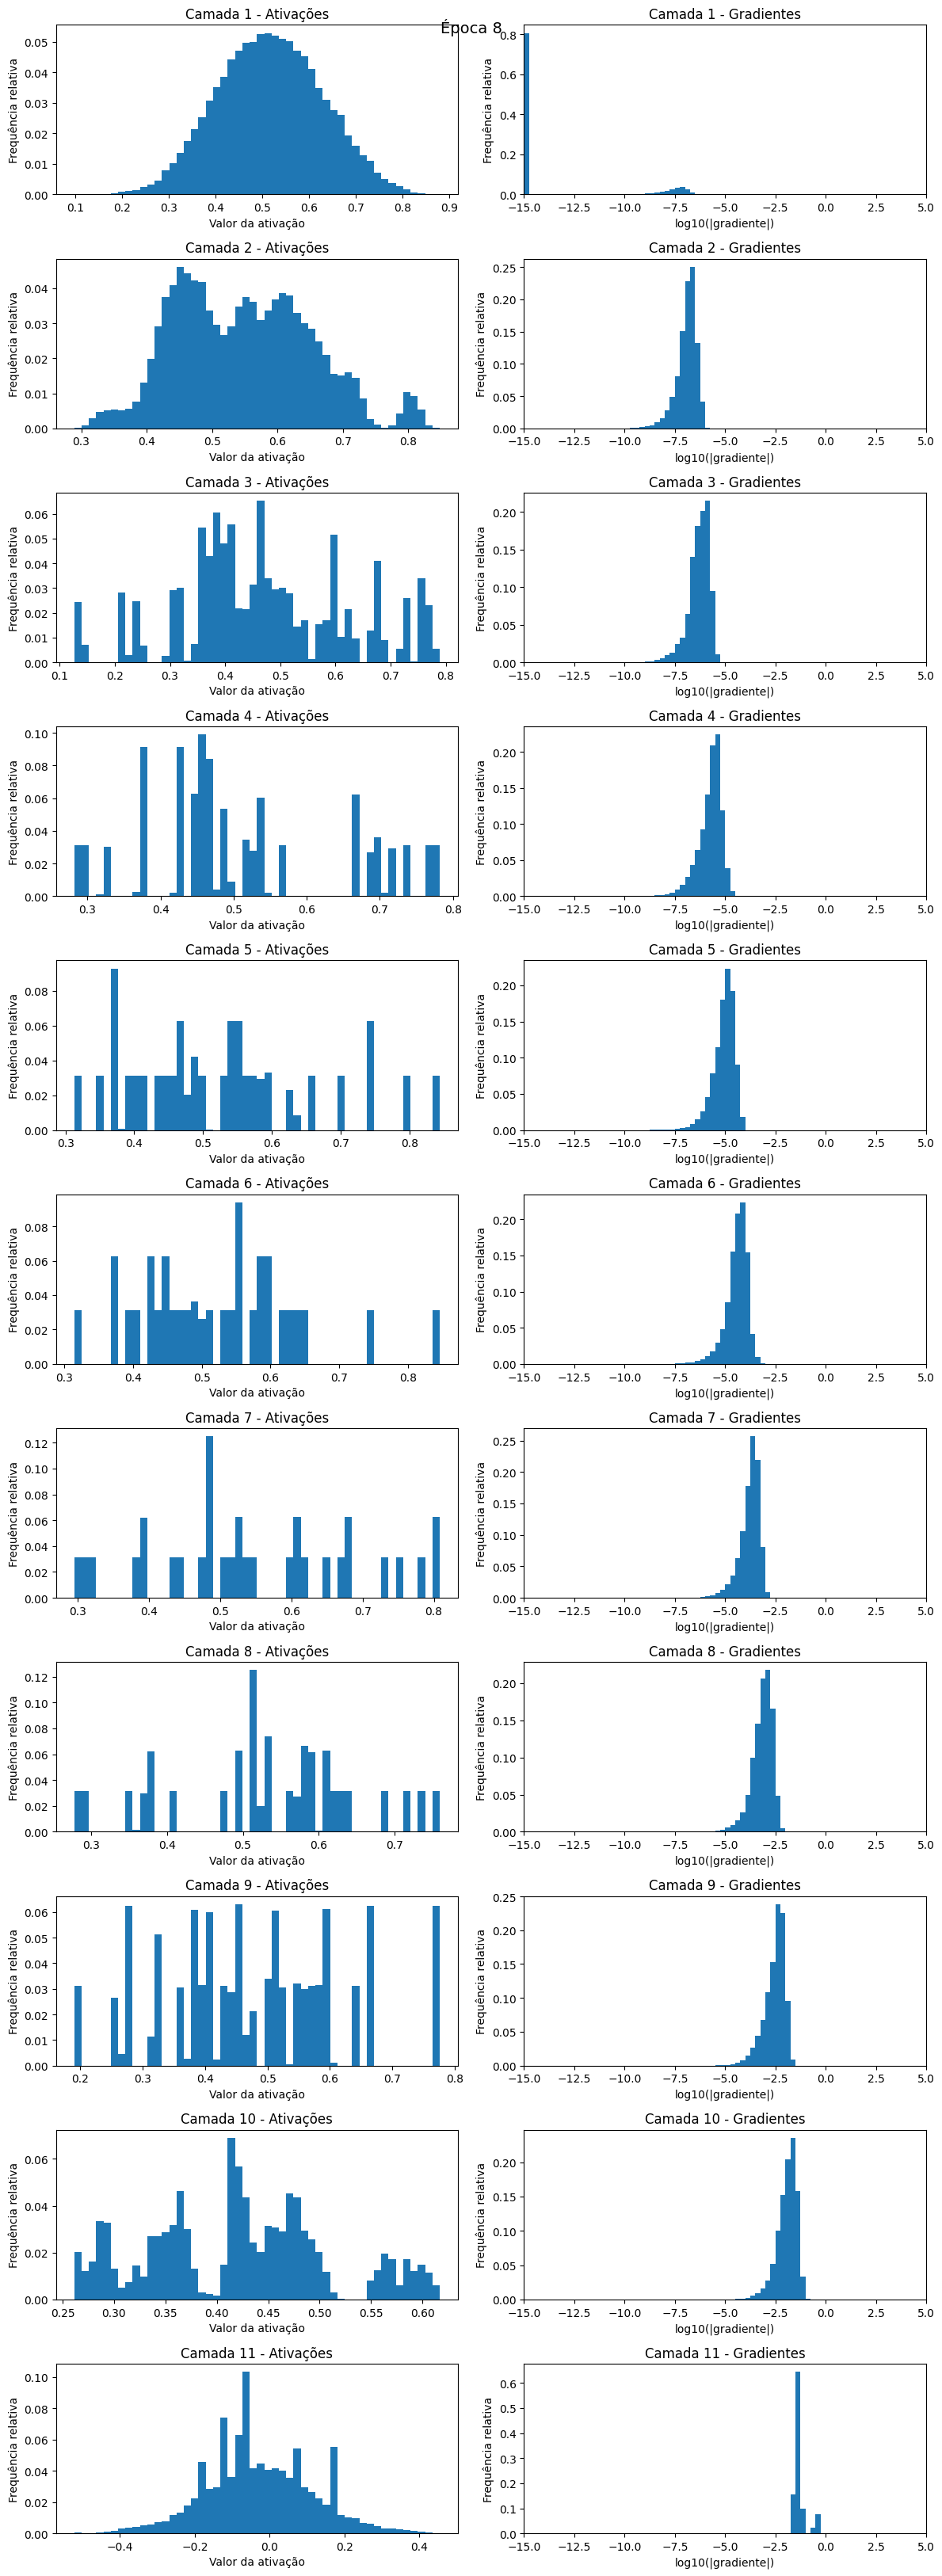

Época: 9 | Loss: 2.326 | Val_Loss: 2.309 | Acc: 8.54% | Val_Acc: 10.00%
Época: 10 | Loss: 2.325 | Val_Loss: 2.309 | Acc: 8.33% | Val_Acc: 10.00%


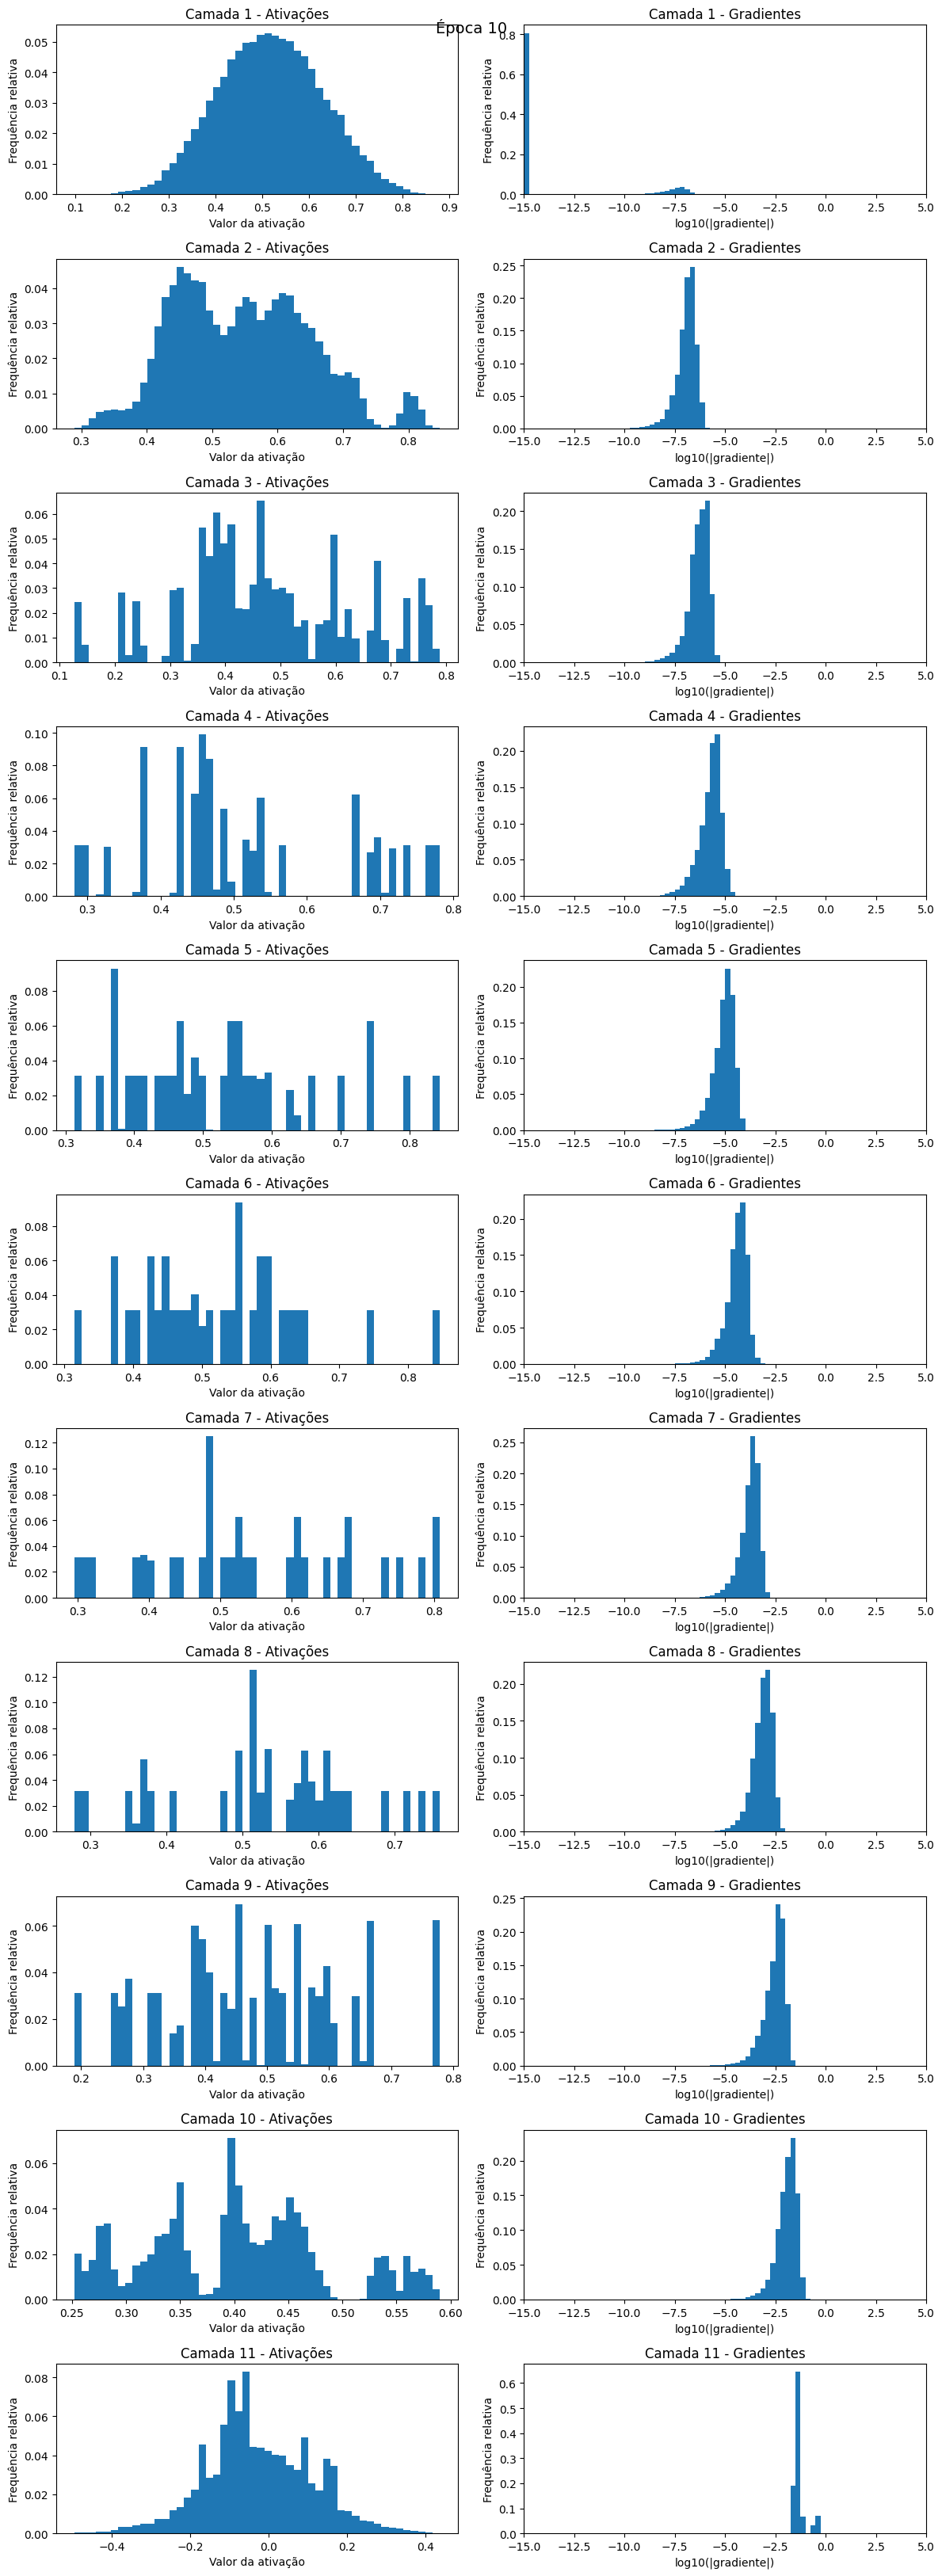

In [14]:
modelo_v = MLP(
    (Dense(784, 32, "Xavier"), True, "sigmoid"),
    (Dense(32, 32, "Xavier"), True, "sigmoid"),
    (Dense(32, 32, "Xavier"), True, "sigmoid"),
    (Dense(32, 32, "Xavier"), True, "sigmoid"),
    (Dense(32, 32, "Xavier"), True, "sigmoid"),
    (Dense(32, 32, "Xavier"), True, "sigmoid"),
    (Dense(32, 32, "Xavier"), True, "sigmoid"),
    (Dense(32, 32, "Xavier"), True, "sigmoid"),
    (Dense(32, 32, "Xavier"), True, "sigmoid"),
    (Dense(32, 32, "Xavier"), True, "sigmoid"),
    (Dense(32, 10, "Xavier"), True, "linear")
)

modelo_v.ativar_monitoramento()

otimizador = SGD(modelo_v, 0.01)

epocas = 10

# Guardar infomações para gerar os gráficos
historico_treino = []
historico_test = []
historico_acc_treino = []
historico_acc_test = []


for epoca in range(epocas):
    limpar_historicos(modelo_v)  # Para limpar os histogramas
    
    # treino
    total_loss = []
    acertos_treino = []
    for i in range(X_mnist_train.peso.shape[0]):
        logits = modelo_v(X_mnist_train[i:i+1])
        loss = SoftmaxCCE(y_mnist_train[i], logits)
        
        acertos_treino.append(int(np.argmax(logits.peso) == y_mnist_train.peso[i]))
        
        loss.backward()
        
        otimizador.passo()
        
        modelo_v.zerar_gradiente()
        
        total_loss.append(float(loss.peso))
    
    # Validação
    validation_loss = []
    acertos_test = []
    for i in range(X_mnist_test.peso.shape[0]):
        logits = modelo_v(X_mnist_test[i:i+1])
        loss = SoftmaxCCE(y_mnist_test[i], logits)
        
        acertos_test.append(int(np.argmax(logits.peso) == y_mnist_test.peso[i]))
    
        
        validation_loss.append(float(loss.peso)) 
    
    historico_treino.append(np.mean(total_loss))
    historico_test.append(np.mean(validation_loss))
    historico_acc_treino.append(np.mean(acertos_treino))   
    historico_acc_test.append(np.mean(acertos_test)) 
    
    print(
    f"Época: {epoca + 1} | "
    f"Loss: {np.mean(total_loss):.3f} | "
    f"Val_Loss: {np.mean(validation_loss):.3f} | "
    f"Acc: {np.mean(acertos_treino):.2%} | "
    f"Val_Acc: {np.mean(acertos_test):.2%}"
    )
    
    if (epoca + 1) % 2 == 0 or epoca == epocas - 1 or epoca == 0:
        plotar_histogramas(modelo_v, epoca + 1)    

# Mostrando o BCE 
(Tinhamos esquecido dele)

In [15]:
# Filtrar apenas as classes 0 e 1
filtro_train = np.isin(y_mnist_train.peso, [0, 1])
filtro_test = np.isin(y_mnist_test.peso, [0, 1])

X_bin_train = criar_tensor(X_mnist_train.peso[filtro_train])
y_bin_train = criar_tensor(y_mnist_train.peso[filtro_train].reshape(-1, 1))

X_bin_test = criar_tensor(X_mnist_test.peso[filtro_test])
y_bin_test = criar_tensor(y_mnist_test.peso[filtro_test].reshape(-1, 1))

In [16]:
modelo_binario = MLP(
    (Dense(784, 32, "He"), True, "reLU"),
    (Dense(32, 16, "He"), True, "reLU"),
    (Dense(16, 1, "Xavier"), True, "sigmoid")
)

modelo_binario.ativar_monitoramento()

otimizador = Adam(modelo_binario, 0.001)

epocas = 30

for epoca in range(epocas):
    total_loss = []
    acertos = []

    for i in np.random.permutation(X_bin_train.peso.shape[0]):
        predicao = modelo_binario(X_bin_train[i:i+1])
        loss = BCE(y_bin_train[i:i+1], predicao)

        acertos.append(
            int((predicao.peso.item() >= 0.5) == y_bin_train.peso[i, 0])
        )

        loss.backward()
        otimizador.passo()
        modelo_binario.zerar_gradiente()

        total_loss.append(loss.peso.item())

    print(
        f"Época {epoca+1} | "
        f"Loss: {np.mean(total_loss):.4f} | "
        f"Acc: {np.mean(acertos):.2%}"
    )

Época 1 | Loss: 0.1905 | Acc: 96.35%
Época 2 | Loss: 0.0229 | Acc: 99.48%
Época 3 | Loss: 0.0034 | Acc: 100.00%
Época 4 | Loss: 0.0015 | Acc: 100.00%
Época 5 | Loss: 0.0008 | Acc: 100.00%
Época 6 | Loss: 0.0006 | Acc: 100.00%
Época 7 | Loss: 0.0004 | Acc: 100.00%
Época 8 | Loss: 0.0003 | Acc: 100.00%
Época 9 | Loss: 0.0002 | Acc: 100.00%
Época 10 | Loss: 0.0002 | Acc: 100.00%
Época 11 | Loss: 0.0001 | Acc: 100.00%
Época 12 | Loss: 0.0001 | Acc: 100.00%
Época 13 | Loss: 0.0001 | Acc: 100.00%
Época 14 | Loss: 0.0001 | Acc: 100.00%
Época 15 | Loss: 0.0000 | Acc: 100.00%
Época 16 | Loss: 0.0000 | Acc: 100.00%
Época 17 | Loss: 0.0000 | Acc: 100.00%
Época 18 | Loss: 0.0000 | Acc: 100.00%
Época 19 | Loss: 0.0000 | Acc: 100.00%
Época 20 | Loss: 0.0000 | Acc: 100.00%
Época 21 | Loss: 0.0000 | Acc: 100.00%
Época 22 | Loss: 0.0000 | Acc: 100.00%
Época 23 | Loss: 0.0000 | Acc: 100.00%
Época 24 | Loss: 0.0000 | Acc: 100.00%
Época 25 | Loss: 0.0000 | Acc: 100.00%
Época 26 | Loss: 0.0000 | Acc: 100.0